# What Are You Worth? Pay in Data Jobs

**Do you know if you are paid fairly?**

In this survey of data professionals, **45% of people feel that they earn below the market, and only 14% feel that they earn above it**. Can both be true? And which things are really connected with higher pay?

In this project, we follow one story in four steps:

1. **Which factors are connected with pay?** We use statistical tests.
2. **What stays when we compare similar people?** We use regression.
3. **How well can we predict pay?** We use machine learning.
4. **Do people know their market value?** We compare real pay, the model's estimate and each person's feeling.

## About the data

The data comes from **Wielka Ankieta Branży Data** (Great Data Industry Survey) by **Crappy Data**. It has 297 people who work with data. We use 264 of them: people who gave their pay and do not belong to a very small position group.

**Pay in this project means average monthly take-home pay** ("na rękę"). This is how the survey asked the question. People were expected to divide their yearly income by 12, after all taxes and social contributions (ZUS). The survey author cannot guarantee that everyone calculated it in exactly this way.

The data rules do not allow us to publish raw answers. For this reason, this notebook shows only group results, hides groups with fewer than 5 people and does not show the lowest or highest salaries.

*Source: Wielka Ankieta Branży Data, Crappy Data.*

## Setup

First, we import the libraries.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LogisticRegression, RidgeCV
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RepeatedKFold,
    RepeatedStratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.stats.multitest import multipletests
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

LightGBM shows the same technical warning many times. It does not change the results, so we hide it to keep the notebook easy to read.

In [2]:
warnings.filterwarnings("ignore", message="X does not have valid feature names")

Next, we set the main values that we use in the whole notebook.

In [3]:
DATA_DIR = "../data/"
SOURCE = "Source: Wielka Ankieta Branży Data, Crappy Data."

# We show only groups with at least this number of people
MIN_PEOPLE = 5

# Colors for the charts
BLUE = "#2a78d6"
RED = "#e34948"
GRAY = "#c3c2b7"
DARK_GRAY = "#52514e"

We remove chart lines that we do not need.

In [4]:
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.bottom"] = False
plt.rcParams["ytick.left"] = False

This function draws the bar charts.

In [5]:
def bar_chart(values, title, subtitle, highlight=None, number_format="{:.1f}", color=BLUE):
    # Choose a color for each bar
    colors = []
    for label in values.index:
        if highlight is None or label in highlight:
            colors.append(color)
        else:
            colors.append(GRAY)

    # Draw the bars
    height = 0.45 * len(values) + 1.8
    fig, ax = plt.subplots(figsize=(8, height))
    bars = ax.barh(values.index.astype(str), values.values, color=colors)

    # Write the value next to each bar
    labels = []
    for value in values.values:
        labels.append(number_format.format(value))
    ax.bar_label(bars, labels, padding=4)

    # Clean the chart and add the text
    ax.set_xlim(0, values.max() * 1.15)
    ax.set_xticks([])
    ax.invert_yaxis()
    fig.suptitle(title, x=0.02, ha="left", fontweight="bold")
    ax.set_title(subtitle, loc="left", fontsize=10, color=DARK_GRAY)
    fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

This function compares groups with the **Kruskal-Wallis test**. It returns two values:

- **p-value:** a small value (below 0.05) means that the difference is unlikely to come only from chance.
- **Eta squared (η²):** the size of the difference. As a rough guide, 0.01 is small, 0.06 is medium and 0.14 is large.

In [6]:
def compare_groups(data, group_column, value_column):
    # Keep only groups that are large enough
    groups = []
    for group_name, group_data in data.groupby(group_column):
        values = group_data[value_column].dropna()
        if len(values) >= MIN_PEOPLE:
            groups.append(values)

    result = stats.kruskal(*groups)

    # Calculate the size of the difference
    people = sum(len(values) for values in groups)
    group_count = len(groups)
    effect_size = (result.statistic - group_count + 1) / (people - group_count)

    return result.pvalue, max(effect_size, 0)

This function makes a pay table for one column and hides small groups.

In [7]:
def pay_table(data, column):
    table = data.groupby(column)["pay"].agg(people="count", median="median")
    return table[table["people"] >= MIN_PEOPLE]

This function draws the median pay of each group. The number of people in each group is shown in brackets.

In [8]:
def median_chart(table, title, highlight=None):
    # Add the number of people to each label
    labels = []
    for name, people in zip(table.index, table["people"]):
        labels.append(f"{name} ({people})")

    # Find the labels that we want to highlight
    highlight_labels = None
    if highlight is not None:
        highlight_labels = []
        for name, label in zip(table.index, labels):
            if name in highlight:
                highlight_labels.append(label)

    values = pd.Series(table["median"].values, index=labels)
    bar_chart(values, title, "Median take-home pay (PLN). Number of people in brackets.", highlight_labels, "{:,.0f}")

This function changes a regression result on log pay into a percentage.

In [9]:
def to_percent(log_value):
    return (np.exp(log_value) - 1) * 100

## Load the data

We need 4 survey tables. Every table has one row for each person.

In [10]:
general = pd.read_csv(DATA_DIR + "0.df_ogolne.csv")
technology = pd.read_csv(DATA_DIR + "2.df_technologie.csv")
work = pd.read_csv(DATA_DIR + "4.df_organizacja_pracy.csv")
well_being = pd.read_csv(DATA_DIR + "5.df_well_being.csv")

We join the tables with the `id` column.

In [11]:
df = general.merge(technology, on="id")
df = df.merge(work, on="id")
df = df.merge(well_being, on="id")

print("People:", df.shape[0])

People: 297


## Prepare the data

The column names are long questions in Polish. We give short English names to the main columns.

In [12]:
column_names = {
    "stanowisko": "position",
    "płeć": "gender",
    "poziom stanowiska (seniority)": "seniority",
    "lata doświadczenia": "experience",
    "w jakiej formie jesteś obecnie zatrudniony/a": "contract",
    "wymiar pracy": "work_time",
    "zarobki": "pay",
    "jaki kapitał ma firma, w której pracujesz": "company_capital",
    "miejsce zamieszkania": "city_size",
    "wielkość firmy, w której pracujesz": "company_size",
    "kierunek wykształcenia": "education_field",
    "jak oceniasz konkurencyjność swojego wynagrodzenia względem rynku": "feeling",
    "w jaki stopniu jesteś zadowolona/y ze swojej pracy": "satisfaction",
    "programowanie | python": "python",
    "narzędzia | snowflake / bigquery / redshift": "cloud_warehouse",
    "narzędzia | excel / google sheets": "excel",
}

df = df.rename(columns=column_names)

Now we translate the answers. We start with the answers about people.

In [13]:
df["gender"] = df["gender"].replace({"kobieta": "Women", "mężczyzna": "Men"})

df["position"] = df["position"].replace({
    "business analyst": "Business analyst",
    "business intelligence (bi) developer": "BI developer",
    "data analyst": "Data analyst",
    "data engineer": "Data engineer",
    "data scientist": "Data scientist",
    "ml/ai engineer": "ML/AI engineer",
    "analytics engineer": "Analytics engineer",
})

df["seniority"] = df["seniority"].replace({
    "stażysta / praktykant": "Intern",
    "junior": "Junior",
    "mid / regular": "Mid / regular",
    "senior": "Senior",
    "lead / expert": "Lead / expert",
    "manager / team leader": "Manager / team leader",
})

df["experience"] = df["experience"].replace({
    "do 2 lat": "Up to 2 years",
    "3–5 lat": "3-5 years",
    "6–10 lat": "6-10 years",
    "11-15 lat": "11-15 years",
    "ponad 15 lat": "Over 15 years",
})

df["city_size"] = df["city_size"].replace({
    "duże miasto (powyżej 500 tys. mieszkańców)": "Big city (over 500,000)",
    "średnie miasto (100–500 tys. mieszkańców)": "Medium city (100,000-500,000)",
    "małe miasto (poniżej 100 tys. mieszkańców)": "Small town (under 100,000)",
    "wieś / obszar wiejski": "Village / rural area",
})

df["education_field"] = df["education_field"].replace({
    "Informatyczne": "Computer science",
    "Inne techniczne (np. inżynieria, automatyka, fizyka, elektrotechnika itp.)": "Other technical",
    "Matematyczne / statystyczne": "Maths / statistics",
    "Ekonomiczne / finansowe": "Economics / finance",
    "Humanistyczne lub społeczne (np. psychologia, socjologia, filologia)": "Humanities / social",
    "Przyrodnicze (np. biologia, chemia, geografia)": "Natural sciences",
    "Inne": "Other",
})

Next, we translate the answers about work and pay.

In [14]:
df["contract"] = df["contract"].replace({
    "umowa o pracę": "Employment contract",
    "b2b (samozatrudnienie)": "B2B",
    "umowa zlecenie / o dzieło": "Civil contract",
    "inne": "Other",
})

df["work_time"] = df["work_time"].replace({
    "pełny etat (ok. 40 godzin tygodniowo)": "Full-time",
    "część etatu": "Part-time",
    "praca w oparciu o rozliczanie godzinowe lub zadaniowe": "Paid by hour or task",
    "inne / trudno powiedzieć": "Other",
})

df["company_capital"] = df["company_capital"].replace({
    "polska": "Polish",
    "międzynarodowa": "International",
    "inne/trudno powiedzieć": "Other / hard to say",
})

df["company_size"] = df["company_size"].replace({
    "freelancer": "Freelancer",
    "bardzo mała firma (< 10 pracowników)": "Under 10 people",
    "mała firma (10-50 pracowników)": "10-50 people",
    "średnia firma (50–500 pracowników)": "50-500 people",
    "duża firma (powyżej 500 pracowników)": "Over 500 people",
})

df["feeling"] = df["feeling"].replace({
    "poniżej średniej": "Below the market",
    "na poziomie średniej rynkowej": "At the market",
    "powyżej średniej": "Above the market",
    "trudno powiedzieć": "Hard to say",
})

We keep only people who gave their pay, because pay is the main topic of this project.

In [15]:
df = df[df["pay"].notna()]

print("People with known pay:", df.shape[0])

People with known pay: 267


The data rules do not allow results that can identify single people. For this reason, we remove analytics engineers, because this group is very small.

In [16]:
df = df[df["position"] != "Analytics engineer"]

print("People in the analysis:", df.shape[0])

People in the analysis: 264


Finally, we check missing answers in the main columns. We do not fill them in here.

In [17]:
main_columns = [
    "position", "gender", "seniority", "experience", "contract", "work_time",
    "company_capital", "company_size", "city_size", "education_field", "feeling", "satisfaction",
]

df[main_columns].isna().sum().sort_values(ascending=False).head(5)

education_field    9
seniority          1
company_capital    1
company_size       1
satisfaction       1
dtype: int64

**Decision:** only a few answers are missing in the main columns, so we keep all 264 people. Each calculation uses the people who answered that question.

---
# Part 1: Which factors are connected with pay?

## 1.1 What does pay look like?

We group pay into bands. We do not show the lowest and highest salaries, because they belong to single people.

In [18]:
band_limits = [0, 6000, 8000, 10000, 12000, 16000, 20000, np.inf]
band_names = ["Under 6,000", "6,000-8,000", "8,000-10,000", "10,000-12,000", "12,000-16,000", "16,000-20,000", "Over 20,000"]

pay_bands = pd.cut(df["pay"], bins=band_limits, labels=band_names, right=False)
band_counts = pay_bands.value_counts().loc[band_names]

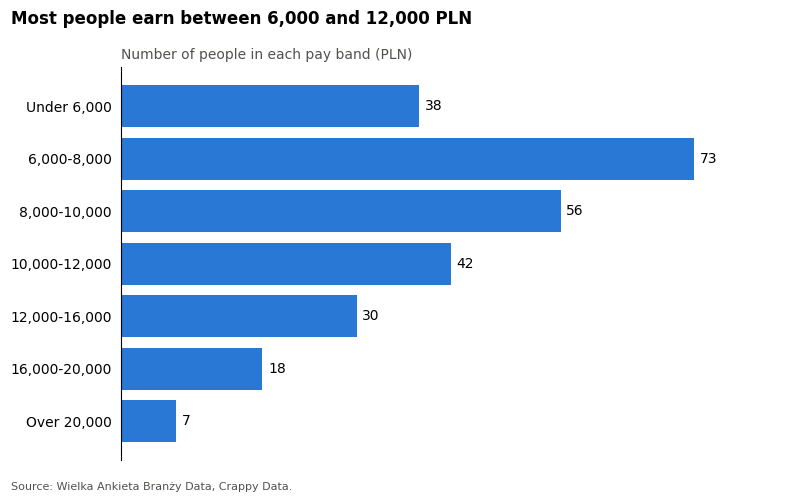

In [19]:
bar_chart(
    band_counts,
    "Most people earn between 6,000 and 12,000 PLN",
    "Number of people in each pay band (PLN)",
    number_format="{:.0f}",
)

Now we calculate the main numbers. **Quartiles** split people into 4 equal groups. For example, 25% of people earn less than the first quartile. We also add the 10th and 90th percentiles, which show where most people are.

We do not use the lowest and highest values, because they would show the pay of single people.

In [20]:
pay_summary = pd.Series({
    "10th percentile": df["pay"].quantile(0.10),
    "1st quartile (25%)": df["pay"].quantile(0.25),
    "Median (50%)": df["pay"].median(),
    "Mean": df["pay"].mean(),
    "3rd quartile (75%)": df["pay"].quantile(0.75),
    "90th percentile": df["pay"].quantile(0.90),
}).round(0)

We show these numbers in a chart. It is similar to a box plot, but it does not show single people:

- **Dark band:** the middle 50% of people, from the 1st to the 3rd quartile.
- **Light band:** the middle 80% of people, from the 10th to the 90th percentile.
- **Line:** the median. **Point:** the mean.

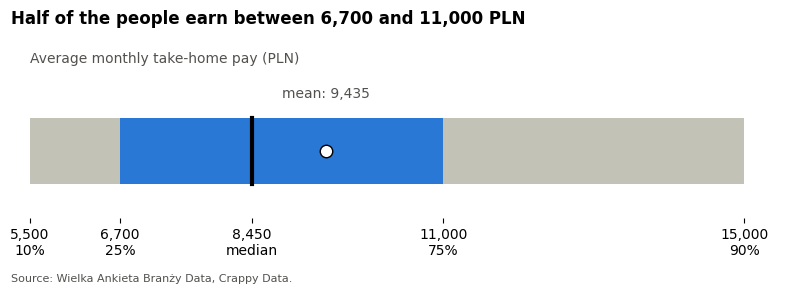

In [21]:
p10 = pay_summary["10th percentile"]
q1 = pay_summary["1st quartile (25%)"]
median = pay_summary["Median (50%)"]
mean = pay_summary["Mean"]
q3 = pay_summary["3rd quartile (75%)"]
p90 = pay_summary["90th percentile"]

fig, ax = plt.subplots(figsize=(8, 2.8))

# Draw the two bands, the median line and the mean point
ax.barh(0, p90 - p10, left=p10, height=0.5, color=GRAY)
ax.barh(0, q3 - q1, left=q1, height=0.5, color=BLUE)
ax.plot([median, median], [-0.25, 0.25], color="black", linewidth=3)
ax.plot(mean, 0, "o", color="white", markeredgecolor="black", markersize=9)

# Write the values under the chart
ax.set_xticks([p10, q1, median, q3, p90])
ax.set_xticklabels([
    f"{p10:,.0f}\n10%",
    f"{q1:,.0f}\n25%",
    f"{median:,.0f}\nmedian",
    f"{q3:,.0f}\n75%",
    f"{p90:,.0f}\n90%",
])
ax.text(mean, 0.4, f"mean: {mean:,.0f}", ha="center", color=DARK_GRAY)

# Clean the chart and add the text
ax.set_yticks([])
ax.set_ylim(-0.5, 0.6)
ax.spines["left"].set_visible(False)
fig.suptitle("Half of the people earn between 6,700 and 11,000 PLN", x=0.02, ha="left", fontweight="bold")
ax.set_title("Average monthly take-home pay (PLN)", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Before we choose a test, we check the **shape** of the data. The Shapiro-Wilk test checks if data has a normal distribution, and skewness shows if the data has a long tail. A value near 0 means that the data is quite symmetric.

In [22]:
log_pay = np.log(df["pay"])

print("Skewness of pay:", round(df["pay"].skew(), 2))
print("Shapiro-Wilk p-value of pay:", stats.shapiro(df["pay"]).pvalue)
print("Skewness of log pay:", round(log_pay.skew(), 2))
print("Shapiro-Wilk p-value of log pay:", stats.shapiro(log_pay).pvalue)

Skewness of pay: 1.69
Shapiro-Wilk p-value of pay: 1.4438189610865625e-14
Skewness of log pay: 0.53
Shapiro-Wilk p-value of log pay: 0.00036531104403978956


**What we see:**

- The median pay is 8,450 PLN, and the middle half of people earn between 6,700 and 11,000 PLN.
- The mean (9,435 PLN) is higher than the median, because some high salaries pull it up.
- Pay has a long tail (skewness 1.69) and it is not normally distributed (p < 0.001). Log pay is much more symmetric (0.53), but it is still not fully normal.

**Decisions:**

- We use the **median** to describe pay.
- We compare groups with the **Kruskal-Wallis test**, because it does not need normally distributed data.
- We use **log pay** in the regression and in the machine learning models.

## 1.2 Contract type

We need to check contract type first, because it can change all later comparisons.

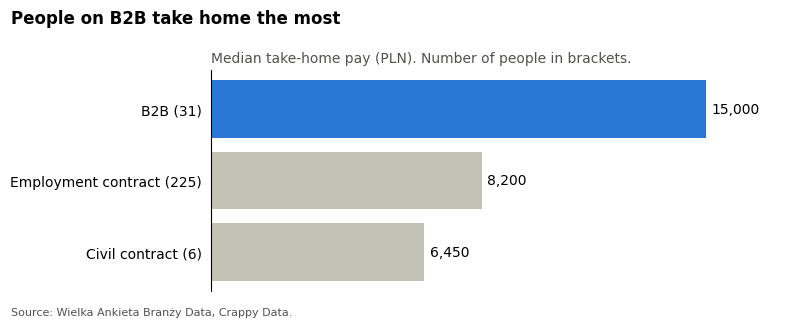

In [23]:
contract_table = pay_table(df, "contract").sort_values("median", ascending=False)

median_chart(contract_table, "People on B2B take home the most", highlight=["B2B"])

In [24]:
contract_p, contract_effect = compare_groups(df, "contract", "pay")

print("p-value:", contract_p)
print("Effect size:", round(contract_effect, 3))

p-value: 1.1644807766612176e-08
Effect size: 0.133


**What we see:** the median is 15,000 PLN on B2B and 8,200 PLN on an employment contract. The effect is close to large (0.133).

**What it means:** pay here is the amount after taxes and ZUS, so this is a large difference in the money that people receive.

**Be careful:** this does not show that B2B is simply better. People on B2B usually have no paid holiday or sick leave, and some of them may have calculated their pay in a different way. They may also do different jobs, so we compare similar people in Part 2.

**Decision:** we include contract type in all fair comparisons, and we repeat the main model for employment contracts only in section 2.5.

## 1.3 Position, seniority and experience

We start with position.

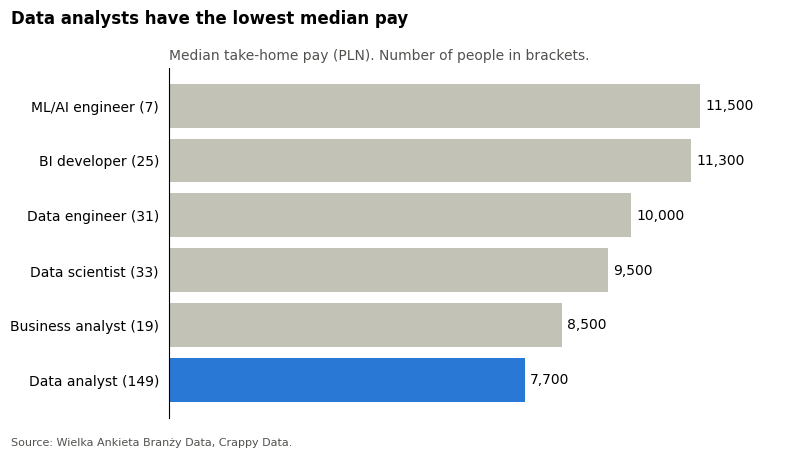

In [25]:
position_table = pay_table(df, "position").sort_values("median", ascending=False)

median_chart(position_table, "Data analysts have the lowest median pay", highlight=["Data analyst"])

In [26]:
position_p, position_effect = compare_groups(df, "position", "pay")

print("p-value:", position_p)
print("Effect size:", round(position_effect, 3))

p-value: 0.0002579845058403151
Effect size: 0.072


Next, we check seniority.

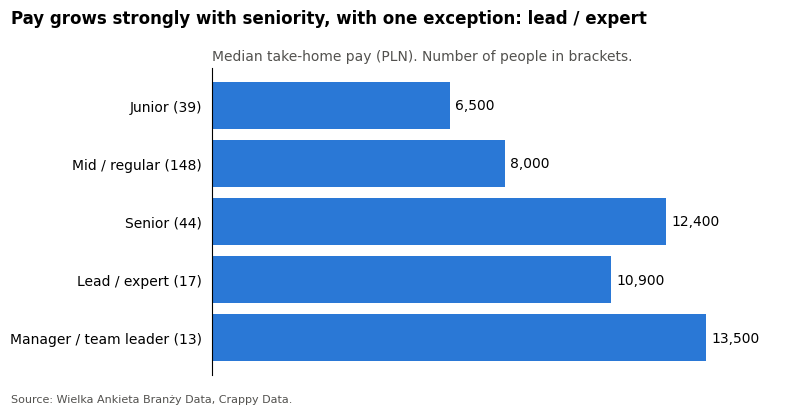

In [27]:
seniority_order = ["Junior", "Mid / regular", "Senior", "Lead / expert", "Manager / team leader"]

seniority_table = pay_table(df, "seniority").loc[seniority_order]

median_chart(seniority_table, "Pay grows strongly with seniority, with one exception: lead / expert")

In [28]:
seniority_p, seniority_effect = compare_groups(df, "seniority", "pay")

print("p-value:", seniority_p)
print("Effect size:", round(seniority_effect, 3))

p-value: 2.5615893263673938e-18
Effect size: 0.331


Finally, we check total experience.

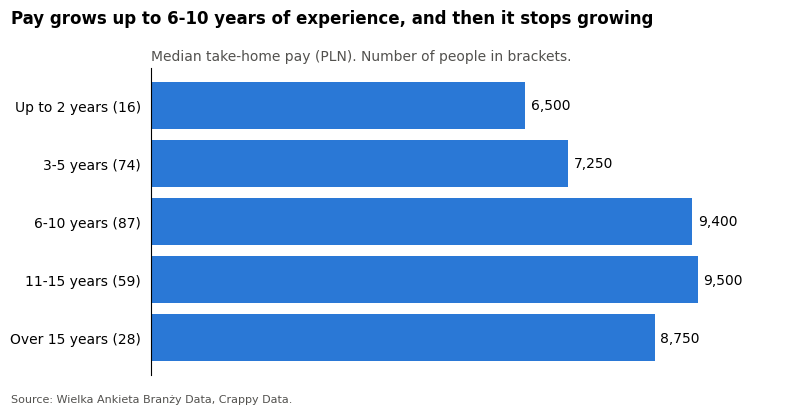

In [29]:
experience_order = ["Up to 2 years", "3-5 years", "6-10 years", "11-15 years", "Over 15 years"]

experience_table = pay_table(df, "experience").loc[experience_order]

median_chart(experience_table, "Pay grows up to 6-10 years of experience, and then it stops growing")

In [30]:
experience_p, experience_effect = compare_groups(df, "experience", "pay")

print("p-value:", experience_p)
print("Effect size:", round(experience_effect, 3))

p-value: 1.3812634709695073e-05
Effect size: 0.092


**What we see:**

- **Seniority has the largest effect of all factors (0.331).** The median grows from 6,500 PLN (junior) to 13,500 PLN (manager). One exception: lead / expert (10,900 PLN) is below senior (12,400 PLN), but this group has only 17 people.
- **Experience has a medium effect (0.092).** Pay grows up to 6-10 years and then stops growing.
- **Position has a medium effect (0.072).** The median is 7,700 PLN for data analysts and 10,000 PLN for data engineers. The ML/AI group is high, but it has only 7 people.

**Decision:** these factors are connected with each other, so we will compare people with similar position, seniority, experience and other background columns in Part 2.

## 1.4 Education and gender

We start with the field of education. The data keeps only the first field from each person's list.

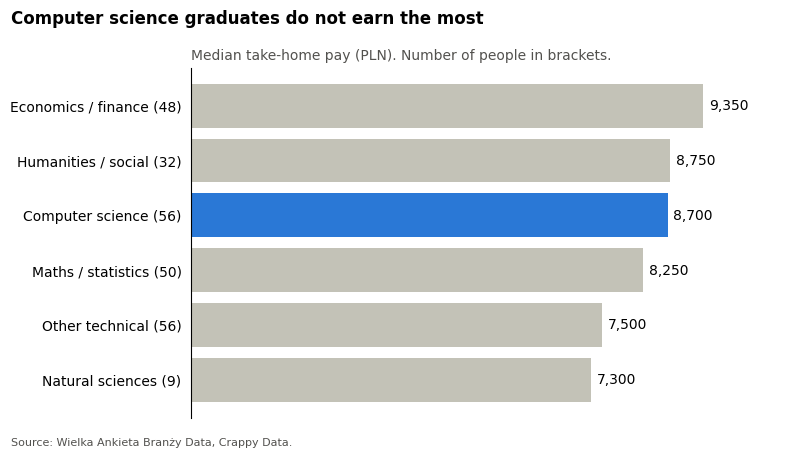

In [31]:
field_table = pay_table(df, "education_field").sort_values("median", ascending=False)

# Gray bars: we do not expect a clear difference here
median_chart(field_table, "Computer science graduates do not earn the most", highlight=["Computer science"])

In [32]:
field_p, field_effect = compare_groups(df, "education_field", "pay")

print("p-value:", round(field_p, 3))
print("Effect size:", round(field_effect, 3))

p-value: 0.21
Effect size: 0.009


Now we check gender.

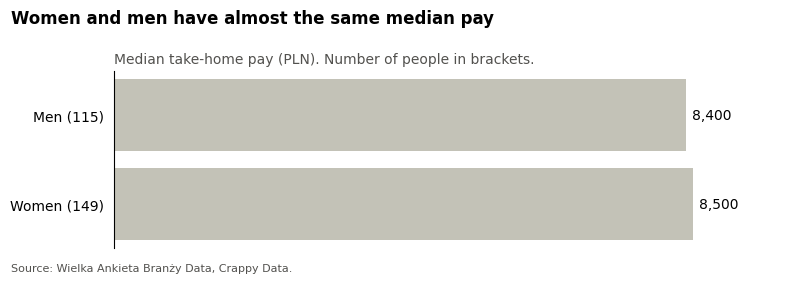

In [33]:
gender_table = pay_table(df, "gender")

median_chart(gender_table, "Women and men have almost the same median pay", highlight=[])

We also check the mean, because it can show a different picture.

In [34]:
df.groupby("gender")["pay"].mean().round(0)

gender
Men      9767.0
Women    9179.0
Name: pay, dtype: float64

In [35]:
gender_p, gender_effect = compare_groups(df, "gender", "pay")

print("p-value:", round(gender_p, 3))
print("Effect size:", round(gender_effect, 3))

p-value: 0.193
Effect size: 0.003


**What we see:**

- **Field of education:** we see no clear difference (p = 0.210). People who studied computer science do not have the highest median.
- **Gender:** the medians are almost the same (8,500 PLN for women and 8,400 PLN for men), and the difference is not clear (p = 0.193).

We test both again in Part 2.

## 1.5 Type of company

We start with the company's capital.

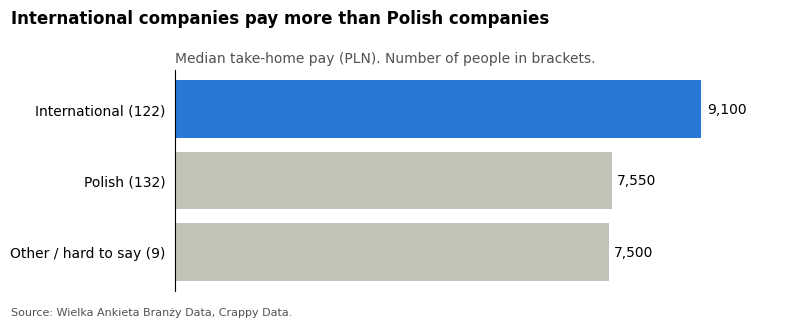

In [36]:
capital_table = pay_table(df, "company_capital").sort_values("median", ascending=False)

median_chart(capital_table, "International companies pay more than Polish companies", highlight=["International"])

In [37]:
capital_p, capital_effect = compare_groups(df, "company_capital", "pay")

print("p-value:", capital_p)
print("Effect size:", round(capital_effect, 3))

p-value: 0.0001075147850485364
Effect size: 0.063


Now we check company size.

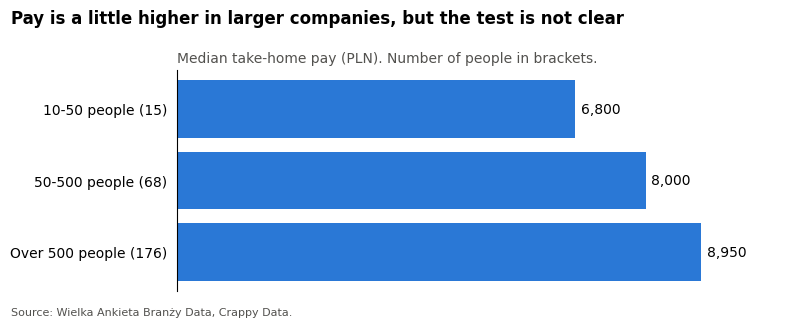

In [38]:
size_order = ["10-50 people", "50-500 people", "Over 500 people"]

size_table = pay_table(df, "company_size").loc[size_order]

median_chart(size_table, "Pay is a little higher in larger companies, but the test is not clear")

In [39]:
size_p, size_effect = compare_groups(df, "company_size", "pay")

print("p-value:", round(size_p, 3))
print("Effect size:", round(size_effect, 3))

p-value: 0.057
Effect size: 0.015


**What we see:**

- **Capital:** the median is 9,100 PLN in international companies and 7,550 PLN in Polish companies. The effect is medium (0.063, p < 0.001).
- **Size:** the median grows with company size, from 6,800 PLN to 8,950 PLN, but the test is not clear (p = 0.057).

**This is interesting**, because a person can choose their employer. Next, we check if the place where people live also matters.

## 1.6 Where people live

The survey does not ask for the exact city, but it asks about the size of the place where people live.

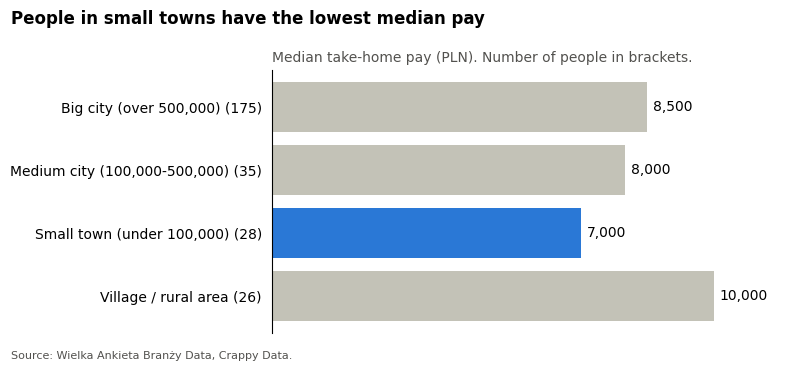

In [40]:
city_order = ["Big city (over 500,000)", "Medium city (100,000-500,000)", "Small town (under 100,000)", "Village / rural area"]

city_table = pay_table(df, "city_size").loc[city_order]

median_chart(city_table, "People in small towns have the lowest median pay", highlight=["Small town (under 100,000)"])

In [41]:
city_p, city_effect = compare_groups(df, "city_size", "pay")

print("p-value:", round(city_p, 3))
print("Effect size:", round(city_effect, 3))

p-value: 0.031
Effect size: 0.023


**What we see:**

- **People in small towns have the lowest median pay** (7,000 PLN). In big cities, it is 8,500 PLN.
- **People in villages have the highest median** (10,000 PLN), but this group has only 26 people. We do not know why. One possible reason is remote work for companies in big cities, but we did not check this.
- **The test is clear (p = 0.031), but the effect is small (0.023).**

**Decision:** city size may change other comparisons, so we include it in the background columns in Part 2 and in the models in Part 3.

Next, we look at something a person can change more easily: their skills.

## 1.7 Python

Python is more common in some positions, and those positions may pay more. So we compare everyone first, and then only data analysts, because this is the largest group. In the `python` column, `1` means that the person uses Python.

In [42]:
data_analysts = df[df["position"] == "Data analyst"]

everyone_python = pay_table(df, "python")
analyst_python = pay_table(data_analysts, "python")

We put the four groups into one table, so we can draw them together.

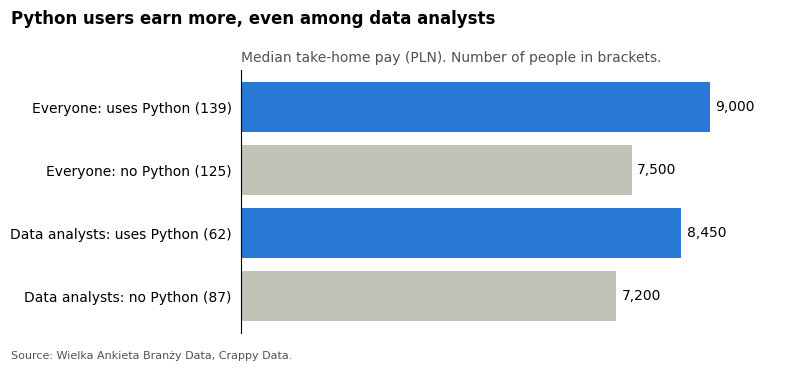

In [43]:
python_table = pd.DataFrame({
    "people": [
        everyone_python.loc[1, "people"],
        everyone_python.loc[0, "people"],
        analyst_python.loc[1, "people"],
        analyst_python.loc[0, "people"],
    ],
    "median": [
        everyone_python.loc[1, "median"],
        everyone_python.loc[0, "median"],
        analyst_python.loc[1, "median"],
        analyst_python.loc[0, "median"],
    ],
}, index=[
    "Everyone: uses Python",
    "Everyone: no Python",
    "Data analysts: uses Python",
    "Data analysts: no Python",
])

median_chart(
    python_table,
    "Python users earn more, even among data analysts",
    highlight=["Everyone: uses Python", "Data analysts: uses Python"],
)

In [44]:
python_p, python_effect = compare_groups(data_analysts, "python", "pay")

print("p-value:", round(python_p, 4))
print("Effect size:", round(python_effect, 3))

p-value: 0.0028
Effect size: 0.054


**What we see:** among data analysts, the median is 8,450 PLN with Python and 7,200 PLN without it (p = 0.003). So Python is connected with higher pay even inside one position. The effect is close to medium (0.054).

## 1.8 Summary of the tests

We ran many tests. When we run many tests, some results can look strong only by chance. The **Holm correction** makes the p-values safer.

In [45]:
test_results = pd.DataFrame(
    [
        ["Seniority", seniority_p, seniority_effect],
        ["Contract", contract_p, contract_effect],
        ["Position", position_p, position_effect],
        ["Experience", experience_p, experience_effect],
        ["Company capital", capital_p, capital_effect],
        ["Python (data analysts)", python_p, python_effect],
        ["Company size", size_p, size_effect],
        ["City size", city_p, city_effect],
        ["Education field", field_p, field_effect],
        ["Gender", gender_p, gender_effect],
    ],
    columns=["factor", "p_value", "effect_size"],
)

test_results["corrected_p"] = multipletests(test_results["p_value"], method="holm")[1]
test_results.sort_values("effect_size", ascending=False).round(4)

,factor,p_value,effect_size,corrected_p
0,Seniority,0.0000,0.3306,0.0000
1,Contract,0.0000,0.1333,0.0000
3,Experience,0.0000,0.0918,0.0001
2,Position,0.0003,0.0721,0.0015
4,Company capital,0.0001,0.0626,0.0008
5,Python (data analysts),0.0028,0.0539,0.0141
7,City size,0.0305,0.0227,0.1221
6,Company size,0.0566,0.0146,0.1699
8,Education field,0.2105,0.0087,0.3864
9,Gender,0.1932,0.0026,0.3864


The chart shows the size of each difference. Blue factors stay clear after the correction.

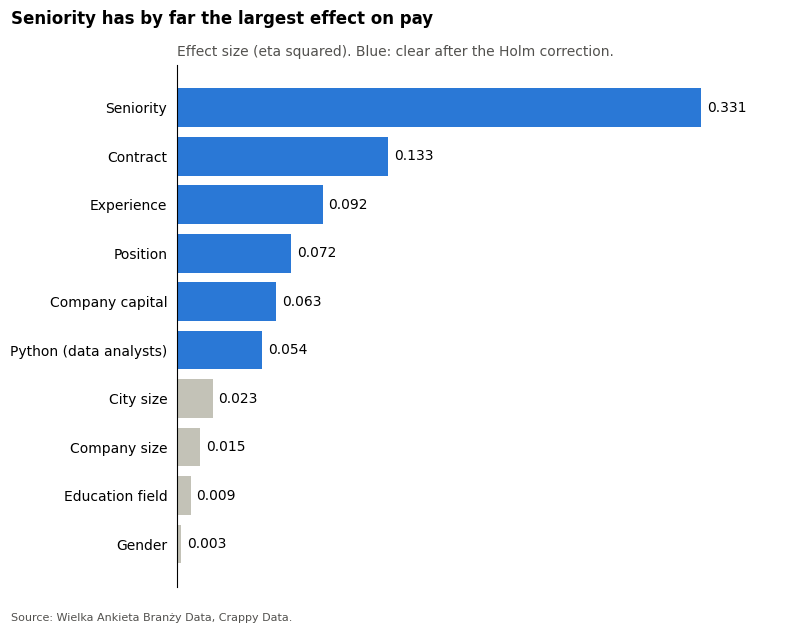

In [46]:
clear_factors = test_results[test_results["corrected_p"] < 0.05]["factor"].tolist()
effect_sizes = test_results.set_index("factor")["effect_size"].sort_values(ascending=False)

bar_chart(
    effect_sizes,
    "Seniority has by far the largest effect on pay",
    "Effect size (eta squared). Blue: clear after the Holm correction.",
    highlight=clear_factors,
    number_format="{:.3f}",
)

**What we see:** after the correction, 6 of 10 factors stay clear: seniority, contract, experience, position, company capital and Python. City size (0.122 after the correction), company size, education field and gender do not.

**Next step:** these tests look at one factor at a time, so they cannot tell us if a factor matters on its own. For example, international companies may simply hire more senior people. Regression can check this.

---
# Part 2: What stays when we compare similar people?

The tests above look at one factor at a time. But factors overlap. For example, Python users may also have higher positions.

A **linear regression** looks at many factors together. Each result shows the connection of one factor when the other factors stay the same.

## 2.1 Which skills should we include?

The survey lists many tools and tasks. First, we make a list of them. We keep skills with at least 15 users and at least 15 non-users.

In [47]:
skill_columns = ["python", "cloud_warehouse", "excel"]
for column in df.columns:
    if column.startswith(("narzędzia |", "programowanie |", "czynności |")):
        skill_columns.append(column)

popular_skills = []
for column in skill_columns:
    users = df[column].sum()
    non_users = df[column].notna().sum() - users
    if users >= 15 and non_users >= 15:
        popular_skills.append(column)

print("Skills to test:", len(popular_skills))

Skills to test: 41


Regression needs log pay. With log pay, the results can be shown as percentages. We also write the background columns that we use to compare similar people.

In [48]:
df["log_pay"] = np.log(df["pay"])

background = "C(position) + C(seniority) + C(experience) + C(contract) + C(work_time) + C(city_size)"

Now we run one regression for each skill.

In [49]:
skill_results = []

for skill in popular_skills:
    skill_data = df.rename(columns={skill: "skill"})
    skill_model = smf.ols("log_pay ~ skill + " + background, data=skill_data).fit()

    skill_results.append({
        "skill": skill,
        "users": int(df[skill].sum()),
        "pay_difference_%": to_percent(skill_model.params["skill"]),
        "p_value": skill_model.pvalues["skill"],
    })

skill_results = pd.DataFrame(skill_results).sort_values("p_value")

We test many skills, so we use the strict Bonferroni correction. It multiplies each p-value by the number of tests.

In [50]:
skill_results["corrected_p"] = (skill_results["p_value"] * len(skill_results)).clip(upper=1)

skill_results.head(6).round(3)

,skill,users,pay_difference_%,p_value,corrected_p
0,python,139,10.990,0.005,0.192
1,cloud_warehouse,39,14.002,0.005,0.216
33,czynności | tworzenie dokumentacji,119,9.019,0.013,0.541
6,narzędzia | airflow,21,16.676,0.019,0.793
2,excel,205,-9.558,0.021,0.879
12,narzędzia | databricks,47,10.795,0.021,0.880


**What we see:** Python (+11.0%) and Snowflake / BigQuery / Redshift (+14.0%) have the smallest p-values. Excel has a negative result (-9.6%).

**Be careful:** after the strict correction, no skill is below 0.05. Python (0.192) and cloud data warehouses (0.216) are the closest. So these results are promising, but they are not strong proof.

**Decision:** we add these three skills to the main model. We chose them after seeing this table, so their p-values in the next model may look a little better than they really are.

## 2.2 Build the main model

First, we make simple yes/no columns. In these columns, 1 means yes and 0 means no.

In [51]:
model_data = df[df["company_capital"].isin(["Polish", "International"])].copy()

model_data["international_company"] = (model_data["company_capital"] == "International").astype(int)
model_data["large_company"] = (model_data["company_size"] == "Over 500 people").astype(int)
model_data["men"] = (model_data["gender"] == "Men").astype(int)

We keep only people with answers to all model questions.

In [52]:
model_columns = ["position", "seniority", "experience", "contract", "work_time", "company_size", "city_size"]
model_data = model_data.dropna(subset=model_columns)

print("People in the model:", model_data.shape[0])

People in the model: 252


We build the model. `cov_type="HC3"` gives safer p-values when the errors are not equal for all people.

In [53]:
factors = "international_company + large_company + python + cloud_warehouse + excel + men"

main_model = smf.ols("log_pay ~ " + factors + " + " + background, data=model_data).fit(cov_type="HC3")

Regression has assumptions, so we check its errors (**residuals**). Their skewness should be close to 0. A skewness near 0 is a good sign, even if the residuals are not perfectly normal.

In [54]:
print("Skewness of residuals:", round(main_model.resid.skew(), 2))
print("Shapiro-Wilk p-value of residuals:", round(stats.shapiro(main_model.resid).pvalue, 4))

Skewness of residuals: -0.18
Shapiro-Wilk p-value of residuals: 0.143


This cell changes the results to percentages.

In [55]:
terms = factors.split(" + ")

main_results = pd.DataFrame({
    "pay_difference_%": to_percent(main_model.params[terms]),
    "ci_low_%": to_percent(main_model.conf_int().loc[terms, 0]),
    "ci_high_%": to_percent(main_model.conf_int().loc[terms, 1]),
    "p_value": main_model.pvalues[terms],
}).round(3)

main_results.sort_values("pay_difference_%", ascending=False)

,pay_difference_%,ci_low_%,ci_high_%,p_value
international_company,13.855,6.753,21.431,0.000
cloud_warehouse,12.234,2.462,22.938,0.013
large_company,11.615,3.088,20.847,0.007
python,9.922,2.276,18.139,0.010
men,-1.358,-8.114,5.896,0.706
excel,-5.984,-14.283,3.117,0.191


A chart shows each result together with its uncertainty. If a line crosses 0, the result is not clear.

In [56]:
chart_data = main_results.sort_values("pay_difference_%").rename(index={
    "international_company": "International company",
    "cloud_warehouse": "Snowflake / BigQuery / Redshift",
    "python": "Python",
    "large_company": "Company with over 500 people",
    "men": "Men (compared with women)",
    "excel": "Excel / Google Sheets",
})

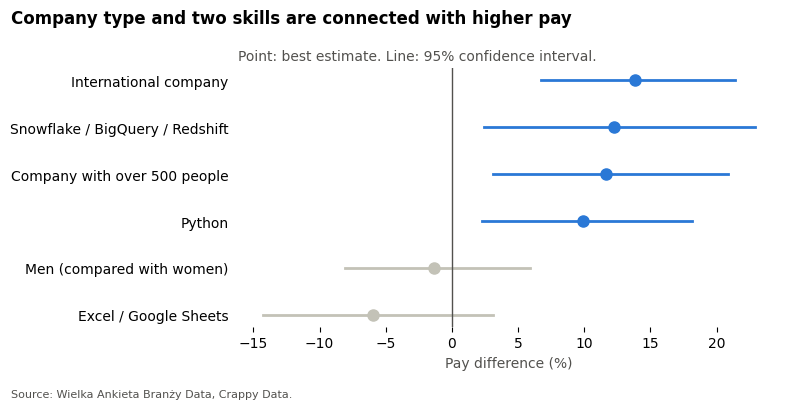

In [57]:
fig, ax = plt.subplots(figsize=(8, 4))

# Draw one line and one point for each factor
for position, (label, row) in enumerate(chart_data.iterrows()):
    is_clear = row["ci_low_%"] > 0 or row["ci_high_%"] < 0
    color = BLUE if is_clear else GRAY
    ax.plot([row["ci_low_%"], row["ci_high_%"]], [position, position], color=color, linewidth=2)
    ax.plot(row["pay_difference_%"], position, "o", color=color, markersize=8)

# Add the zero line and the labels
ax.axvline(0, color=DARK_GRAY, linewidth=1)
ax.set_yticks(range(len(chart_data)))
ax.set_yticklabels(chart_data.index)
ax.set_xlabel("Pay difference (%)", color=DARK_GRAY)
ax.spines["left"].set_visible(False)

fig.suptitle("Company type and two skills are connected with higher pay", x=0.02, ha="left", fontweight="bold")
ax.set_title("Point: best estimate. Line: 95% confidence interval.", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**R²** shows how much of the difference in log pay a model explains. We compare our model with a model that has only the background columns.

In [58]:
background_model = smf.ols("log_pay ~ " + background, data=model_data).fit()

print("R² with background only:", round(background_model.rsquared, 3))
print("R² with our factors:", round(main_model.rsquared, 3))

R² with background only: 0.555
R² with our factors: 0.645


**How to read it:** the percentage is the difference in pay compared with similar people.

**Assumptions:** the residuals look good. Their skewness is close to 0 (-0.18), and the Shapiro-Wilk test finds no problem (p = 0.143).

**What we see:**

- **International company: +13.9%** (from +6.8% to +21.4%). This is the clearest result (p < 0.001).
- **Snowflake / BigQuery / Redshift: +12.2%** (from +2.5% to +22.9%).
- **Company with over 500 people: +11.6%** (from +3.1% to +20.8%).
- **Python: +9.9%** (from +2.3% to +18.1%).
- **Excel and gender:** no clear difference.

R² grows from 0.555 to 0.645, so these factors add about 9 percentage points to what the background columns explain.

**A wider look:** the intervals are wide. For example, the Python result could be close to +2% or close to +18%. So we should look at the direction of the results, not only at the exact number.

## 2.3 Does field of education add anything?

We add field of education to the model. Then an F-test checks if the model becomes clearly better.

In [59]:
field_data = model_data.dropna(subset=["education_field"])
field_data = field_data[field_data["education_field"] != "Other"]

model_without_field = smf.ols("log_pay ~ " + factors + " + " + background, data=field_data).fit()
model_with_field = smf.ols("log_pay ~ C(education_field) + " + factors + " + " + background, data=field_data).fit()

f_value, f_p, degrees = model_with_field.compare_f_test(model_without_field)

print("People:", field_data.shape[0])
print("F-test p-value:", round(f_p, 3))

People: 240
F-test p-value: 0.913


**What we see:** adding field of education does not make the model better (p = 0.913). Among similar people, we do not see a pay difference between fields.

**Be careful:** the data keeps only the first field from each person's list, so this result is not perfect.

## 2.4 Does the gender result depend on the comparison?

The main model compares people with the same position and seniority. But if it is harder for one gender to get promoted, this comparison can hide the gap. So we remove position and seniority and test gender again.

In [60]:
gender_formula = "log_pay ~ men + C(experience) + C(contract) + C(work_time) + C(city_size)"

gender_model = smf.ols(gender_formula, data=model_data).fit(cov_type="HC3")

print("Pay difference for men (%):", round(to_percent(gender_model.params["men"]), 1))
print("From (%):", round(to_percent(gender_model.conf_int().loc["men", 0]), 1))
print("To (%):", round(to_percent(gender_model.conf_int().loc["men", 1]), 1))
print("p-value:", round(gender_model.pvalues["men"], 3))

Pay difference for men (%): 1.7
From (%): -6.8
To (%): 11.1
p-value: 0.699


**What we see:** without position and seniority, the result for men is +1.7% (from -6.8% to +11.1%, p = 0.699). So we see no clear gender gap in either comparison.

**Be careful:** this does not prove that there is no gap. The interval is wide, so a gap of several percent is still possible. People also chose to take part in this survey, so the sample may not describe the whole industry.

## 2.5 Do the results stay for employment contracts only?

B2B jobs have different conditions, and some people on B2B may have calculated their take-home pay in a different way. To check if this changes our results, we repeat the model only for full-time people with an employment contract.

In [61]:
is_employment = model_data["contract"] == "Employment contract"
is_full_time = model_data["work_time"] == "Full-time"

employment_data = model_data[is_employment & is_full_time]

print("People in this check:", employment_data.shape[0])

People in this check: 208


In [62]:
employment_formula = "log_pay ~ " + factors + " + C(position) + C(seniority) + C(experience) + C(city_size)"

employment_model = smf.ols(employment_formula, data=employment_data).fit(cov_type="HC3")

We put both results side by side.

In [63]:
comparison = pd.DataFrame({
    "all_people_%": main_results["pay_difference_%"],
    "all_people_p": main_results["p_value"],
    "employment_only_%": to_percent(employment_model.params[terms]),
    "employment_only_p": employment_model.pvalues[terms],
}).round(3)

comparison.sort_values("all_people_%", ascending=False)

,all_people_%,all_people_p,employment_only_%,employment_only_p
international_company,13.855,0.000,11.646,0.002
cloud_warehouse,12.234,0.013,9.297,0.088
large_company,11.615,0.007,9.997,0.029
python,9.922,0.010,11.623,0.007
men,-1.358,0.706,2.481,0.495
excel,-5.984,0.191,-7.334,0.118


**What we see:**

- **International company (+11.6%, p = 0.002) and Python (+11.6%, p = 0.007) stay clear.** These are our most reliable results.
- **Large companies stay clear too (+10.0%, p = 0.029).**
- **Cloud data warehouses become weaker (+9.3%, p = 0.088).** The direction stays the same, but the result is no longer clear.
- **Gender and Excel stay unclear.**

**What we learned in Part 2:** where you work and whether you use Python are connected with pay, even among similar people. But these connections do not prove a cause. For example, people who use Python may also do more complex work.

---
# Part 3: How well can machine learning predict pay?

Regression showed connections inside our data. Now we ask a different question: **can a model predict the pay of people it has never seen?**

## 3.1 Prepare the data for the models

We use log pay as the target. We do not use gender as a feature, because we want the model to compare people by their job. We test two sets of features.

In [64]:
job_features = ["position", "seniority", "experience", "contract", "work_time"]
company_features = ["company_capital", "company_size"]
city_features = ["city_size"]

tool_features = ["python", "cloud_warehouse", "excel"]
for column in df.columns:
    if column.startswith(("narzędzia |", "programowanie |")):
        tool_features.append(column)

feature_sets = {
    "Job + company + city": job_features + company_features + city_features,
    "Job + company + city + tools": job_features + company_features + city_features + tool_features,
}

Models need numbers, so we prepare the columns with a **pipeline**:

- **Missing answers:** we fill them in with the most common answer.
- **Text columns:** one-hot encoding changes them into 0/1 columns. Rare answers go into one shared group.
- **Number columns:** we put them on the same scale.

The pipeline learns these steps only from training data. This prevents **data leakage**.

In [65]:
def make_model(features, model):
    text_columns = []
    number_columns = []
    for column in features:
        if df[column].dtype == object:
            text_columns.append(column)
        else:
            number_columns.append(column)

    text_steps = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", min_frequency=MIN_PEOPLE, sparse_output=False),
    )
    number_steps = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )
    prepare = ColumnTransformer([
        ("text", text_steps, text_columns),
        ("numbers", number_steps, number_columns),
    ])

    return make_pipeline(prepare, model)

## 3.2 Choose the models

We compare simple and complex models. Many models have settings (**hyperparameters**). `GridSearchCV` tries different settings and keeps the best ones. It uses only training data, so the final test stays fair.

In [66]:
inner_splits = KFold(n_splits=4, shuffle=True, random_state=1)


def tuned(model, settings):
    return GridSearchCV(model, settings, cv=inner_splits, scoring="r2", n_jobs=-1)

First, we add a baseline and two linear models. **Baseline** always predicts the mean, and a useful model must be better than this. **Ridge** and **Lasso** are linear models that protect against too many features. Lasso can also remove features.

In [67]:
models = {
    "Baseline": DummyRegressor(),
    "Ridge": RidgeCV(alphas=np.logspace(-2, 3, 12)),
    "Lasso": LassoCV(cv=4, random_state=0, max_iter=20000),
}

Next, we add a **decision tree**. It is the easiest model to explain, because it is a list of simple yes/no rules.

In [68]:
models["Decision tree (tuned)"] = tuned(
    DecisionTreeRegressor(random_state=0),
    {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [5, 10, 20]},
)

**Random Forest** builds many trees at the same time and takes their average.

In [69]:
models["Random Forest (tuned)"] = tuned(
    RandomForestRegressor(n_estimators=200, random_state=0),
    {"min_samples_leaf": [1, 3, 5, 10], "max_features": [0.3, 0.6, 1.0]},
)

**Boosting** builds small trees one after another, and each new tree tries to fix the errors of the earlier trees. We test XGBoost with its default settings first.

In [70]:
models["XGBoost (default)"] = XGBRegressor(random_state=0, n_jobs=1, verbosity=0)

Now we add the tuned versions.

In [71]:
xgboost_settings = {
    "n_estimators": [100, 300],
    "learning_rate": [0.02, 0.05],
    "max_depth": [1, 2, 3],
    "min_child_weight": [1, 5],
    "reg_lambda": [1, 10],
}

models["XGBoost (tuned)"] = tuned(
    XGBRegressor(random_state=0, n_jobs=1, verbosity=0, subsample=0.8, colsample_bytree=0.8),
    xgboost_settings,
)

In [72]:
lightgbm_settings = {
    "n_estimators": [100, 300],
    "learning_rate": [0.02, 0.05],
    "num_leaves": [2, 4, 8],
    "min_child_samples": [5, 20],
    "reg_lambda": [0, 10],
}

models["LightGBM (tuned)"] = tuned(
    LGBMRegressor(random_state=0, n_jobs=1, verbose=-1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8),
    lightgbm_settings,
)

## 3.3 Compare the models

We use **cross-validation**. The data is split into 5 parts, and each part is used once as new, unseen data. We repeat this 5 times with different splits, so the result does not depend on one lucky split.

**Note:** the next cell can take several minutes, because it trains many models.

In [73]:
target = df["log_pay"]
splits = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)

model_results = []

for set_name, features in feature_sets.items():
    for model_name, model in models.items():
        scores = cross_validate(
            make_model(features, model),
            df[features],
            target,
            cv=splits,
            scoring=["r2", "neg_mean_absolute_error"],
            return_train_score=True,
        )
        model_results.append({
            "features": set_name,
            "model": model_name,
            "r2_new_people": scores["test_r2"].mean(),
            "r2_std": scores["test_r2"].std(),
            "r2_training": scores["train_r2"].mean(),
            "typical_error_%": to_percent(-scores["test_neg_mean_absolute_error"].mean()),
        })

model_results = pd.DataFrame(model_results)

First, we look at all results for each set of features.

In [74]:
model_results[model_results["features"] == "Job + company + city"].sort_values("r2_new_people", ascending=False).round(3)

,features,model,r2_new_people,r2_std,r2_training,typical_error_%
2,Job + company + city,Lasso,0.503,0.115,0.620,22.817
1,Job + company + city,Ridge,0.494,0.112,0.619,23.016
7,Job + company + city,LightGBM (tuned),0.490,0.119,0.631,23.193
6,Job + company + city,XGBoost (tuned),0.473,0.136,0.643,23.526
4,Job + company + city,Random Forest (tuned),0.421,0.128,0.692,24.709
5,Job + company + city,XGBoost (default),0.281,0.162,0.903,27.443
3,Job + company + city,Decision tree (tuned),0.262,0.186,0.494,28.155
0,Job + company + city,Baseline,-0.022,0.032,0.000,35.562


In [75]:
model_results[model_results["features"] == "Job + company + city + tools"].sort_values("r2_new_people", ascending=False).round(3)

,features,model,r2_new_people,r2_std,r2_training,typical_error_%
15,Job + company + city + tools,LightGBM (tuned),0.514,0.098,0.669,22.557
14,Job + company + city + tools,XGBoost (tuned),0.511,0.108,0.678,22.595
10,Job + company + city + tools,Lasso,0.502,0.093,0.663,23.341
9,Job + company + city + tools,Ridge,0.475,0.109,0.696,24.069
12,Job + company + city + tools,Random Forest (tuned),0.433,0.116,0.811,24.531
11,Job + company + city + tools,Decision tree (tuned),0.272,0.171,0.520,27.767
13,Job + company + city + tools,XGBoost (default),0.265,0.173,0.994,27.600
8,Job + company + city + tools,Baseline,-0.022,0.032,0.000,35.562


Now we show the 8 best combinations in a chart.

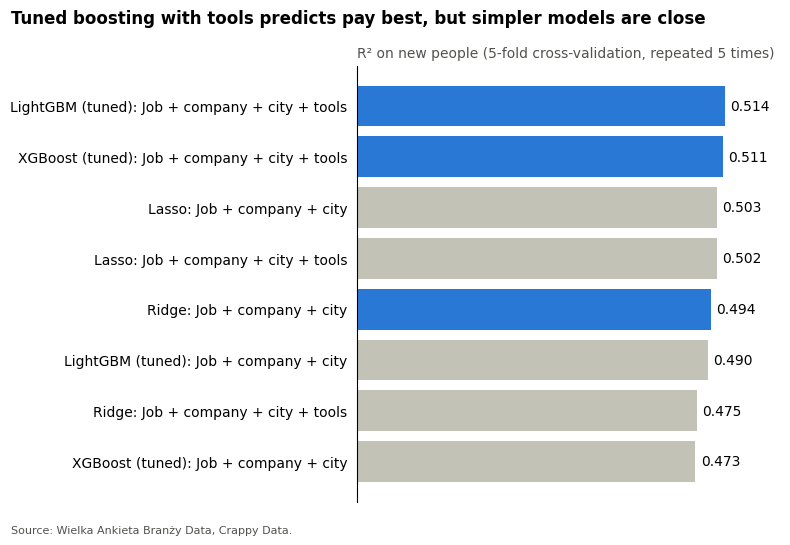

In [76]:
chart_models = model_results.copy()
chart_models["name"] = chart_models["model"] + ": " + chart_models["features"]
chart_models = chart_models.set_index("name")["r2_new_people"].sort_values(ascending=False).head(8)

bar_chart(
    chart_models,
    "Tuned boosting with tools predicts pay best, but simpler models are close",
    "R² on new people (5-fold cross-validation, repeated 5 times)",
    highlight=["XGBoost (tuned): Job + company + city + tools", "LightGBM (tuned): Job + company + city + tools", "Ridge: Job + company + city"],
    number_format="{:.3f}",
)

**What we see:**

- **All real models are clearly better than the baseline.** The baseline has a typical error of about 36%. The best models have about 23%.
- **Tuned LightGBM (R² = 0.514) and XGBoost (0.511) with tools are the most accurate.** They are practically equal.
- **Simpler models are close.** Lasso has 0.502 with tools and 0.503 without them. Ridge has 0.494 with job, company and city columns.
- **A simple decision tree is much weaker** (0.262), and tuned Random Forest does not beat the best simple linear models (0.433 with tools).

**Be careful:** R² changes by about 0.1 between different splits, so small differences between the best models are not important. Tools add only a little to the prediction.

### What is overfitting?

A model **overfits** when it learns the training data too well, but it cannot predict new people. We compare XGBoost with its default settings and with tuned settings.

In [77]:
is_xgboost = model_results["model"].str.startswith("XGBoost")
is_tools = model_results["features"] == "Job + company + city + tools"

overfit = model_results[is_xgboost & is_tools].set_index("model")

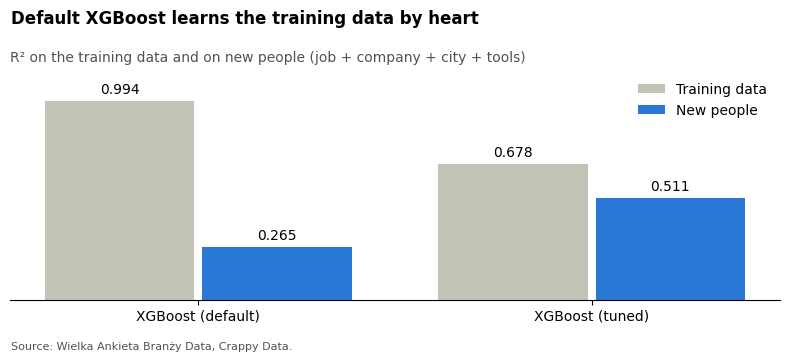

In [78]:
fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(overfit))

# Gray bars: training data. Blue bars: new people.
training_bars = ax.bar(positions - 0.2, overfit["r2_training"], width=0.38, color=GRAY, label="Training data")
new_bars = ax.bar(positions + 0.2, overfit["r2_new_people"], width=0.38, color=BLUE, label="New people")
ax.bar_label(training_bars, [f"{value:.3f}" for value in overfit["r2_training"]], padding=3)
ax.bar_label(new_bars, [f"{value:.3f}" for value in overfit["r2_new_people"]], padding=3)

ax.set_xticks(positions)
ax.set_xticklabels(overfit.index)
ax.set_yticks([])
ax.set_ylim(0, 1.15)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.legend(frameon=False, loc="upper right")

fig.suptitle("Default XGBoost learns the training data by heart", x=0.02, ha="left", fontweight="bold")
ax.set_title("R² on the training data and on new people (job + company + city + tools)", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**What we see:** XGBoost with default settings has almost perfect results on the training data (0.994), but it is weak on new people (0.265). This is clear overfitting. With tuned settings, the two numbers are much closer (0.678 and 0.511).

**What we learned:** with a small dataset, settings can matter more than the name of the algorithm.

## 3.4 Do we need more people or more information?

A **learning curve** trains a model on more and more people. If the result on new people keeps growing, more people would probably help. If it stops growing, we probably need new information, not more people.

First, we find the best LightGBM settings for the data with tools.

In [79]:
tools_features = feature_sets["Job + company + city + tools"]

lightgbm_search = make_model(tools_features, models["LightGBM (tuned)"]).fit(df[tools_features], target)
best_lightgbm_settings = lightgbm_search[-1].best_params_

print(best_lightgbm_settings)

{'learning_rate': 0.05, 'min_child_samples': 5, 'n_estimators': 300, 'num_leaves': 2, 'reg_lambda': 0}


We use these settings to make a final LightGBM model. We chose the settings with all the data, so we use this model only for the learning curve and the checks below, and not to measure its accuracy.

In [80]:
final_lightgbm = LGBMRegressor(
    random_state=0, n_jobs=1, verbose=-1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    **best_lightgbm_settings,
)

Now we calculate the learning curves.

In [81]:
curve_models = {
    "Ridge (job + company + city)": (feature_sets["Job + company + city"], RidgeCV(alphas=np.logspace(-2, 3, 12))),
    "Random Forest (job + company + city)": (feature_sets["Job + company + city"], RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=0)),
    "LightGBM (job + company + city + tools)": (tools_features, final_lightgbm),
}

curve_splits = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)
curve_rows = []

for name, (features, model) in curve_models.items():
    sizes, train_scores, test_scores = learning_curve(
        make_model(features, model),
        df[features],
        target,
        cv=curve_splits,
        train_sizes=[0.3, 0.5, 0.7, 1.0],
        scoring="r2",
    )
    for size, train_score, test_score in zip(sizes, train_scores.mean(axis=1), test_scores.mean(axis=1)):
        curve_rows.append({"model": name, "people": size, "r2_training": train_score, "r2_new_people": test_score})

curve_results = pd.DataFrame(curve_rows)

This chart shows the results on new people.

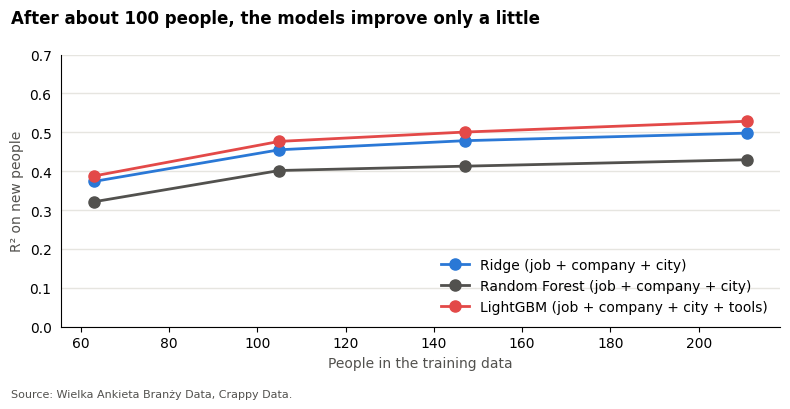

In [82]:
curve_colors = {
    "Ridge (job + company + city)": BLUE,
    "Random Forest (job + company + city)": DARK_GRAY,
    "LightGBM (job + company + city + tools)": RED,
}

fig, ax = plt.subplots(figsize=(8, 4))

for name, color in curve_colors.items():
    rows = curve_results[curve_results["model"] == name]
    ax.plot(rows["people"], rows["r2_new_people"], marker="o", markersize=8, linewidth=2, color=color, label=name)

ax.set_ylim(0, 0.7)
ax.set_xlabel("People in the training data", color=DARK_GRAY)
ax.set_ylabel("R² on new people", color=DARK_GRAY)
ax.spines["bottom"].set_visible(True)
ax.grid(axis="y", color="#e6e5e0", linewidth=1)
ax.legend(frameon=False, loc="lower right")

fig.suptitle("After about 100 people, the models improve only a little", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**What we see:**

- **The biggest improvement comes early.** All models improve between 63 and 105 people.
- **After that, growth is slow.** From 105 to 211 people, Ridge grows from 0.455 to 0.498 and Random Forest from 0.402 to 0.429. LightGBM grows from 0.477 to 0.528. Its results here may look a little too good, because we chose its settings with all the data.
- **The best settings for LightGBM are very simple.** Each tree has only 2 leaves, so complex combinations of features do not seem to be needed.

**What it means:** more people would probably help only a little. To predict pay much better, the survey would need new information, for example the exact city, exact skill level or results at work.

## 3.5 Which features matter most?

We use **permutation importance**. We mix the values of one column and check how much worse the model gets. If the model gets much worse, the column was important. We do this only on unseen data.

This function calculates the importance for one model.

In [83]:
def average_importance(features, model):
    importance_rows = []
    splitter = KFold(n_splits=5, shuffle=True, random_state=0)

    for train_rows, test_rows in splitter.split(df):
        train = df.iloc[train_rows]
        test = df.iloc[test_rows]

        fitted = make_model(features, model).fit(train[features], train["log_pay"])
        importance = permutation_importance(
            fitted, test[features], test["log_pay"], scoring="r2", n_repeats=10, random_state=0,
        )
        importance_rows.append(importance.importances_mean)

    return pd.Series(np.mean(importance_rows, axis=0), index=features)

We start with Ridge.

In [84]:
best_features = feature_sets["Job + company + city"]
best_model = RidgeCV(alphas=np.logspace(-2, 3, 12))

feature_labels = {
    "seniority": "Seniority",
    "contract": "Contract",
    "position": "Position",
    "company_capital": "Company capital",
    "experience": "Experience",
    "company_size": "Company size",
    "work_time": "Work time",
    "city_size": "City size",
    "python": "Python",
    "cloud_warehouse": "Snowflake / BigQuery / Redshift",
    "excel": "Excel / Google Sheets",
}

ridge_importance = average_importance(best_features, best_model)
ridge_importance = ridge_importance.rename(index=feature_labels).sort_values(ascending=False)

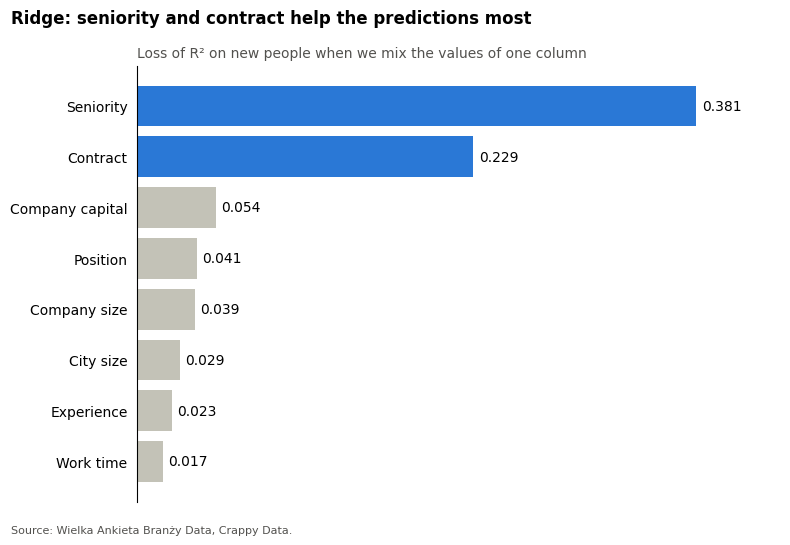

In [85]:
bar_chart(
    ridge_importance,
    "Ridge: seniority and contract help the predictions most",
    "Loss of R² on new people when we mix the values of one column",
    highlight=["Seniority", "Contract"],
    number_format="{:.3f}",
)

Now we do the same for LightGBM. It also uses tools, so we can see which tools help.

In [86]:
lightgbm_importance = average_importance(tools_features, final_lightgbm)
lightgbm_importance = lightgbm_importance.rename(index=feature_labels)

# Remove the Polish start of the tool names, for example "narzędzia | airflow"
lightgbm_importance = lightgbm_importance.rename(index=lambda name: name.split(" | ")[-1])

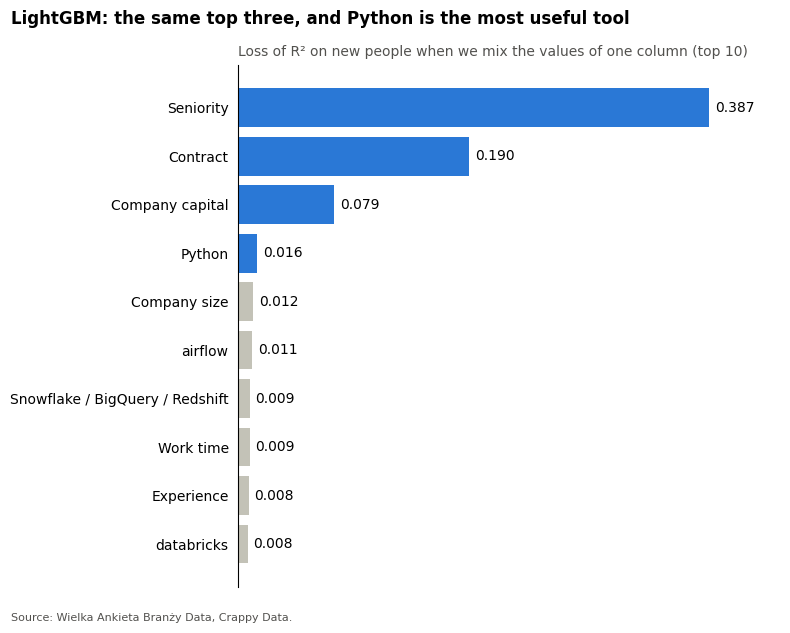

In [87]:
bar_chart(
    lightgbm_importance.sort_values(ascending=False).head(10),
    "LightGBM: the same top three, and Python is the most useful tool",
    "Loss of R² on new people when we mix the values of one column (top 10)",
    highlight=["Seniority", "Contract", "Company capital", "Python"],
    number_format="{:.3f}",
)

**What we see:**

- **Both models agree on the top three:** seniority (0.381 in Ridge and 0.387 in LightGBM), contract (0.229 and 0.190) and company capital (0.054 and 0.079).
- **City size adds a little** (0.029 in Ridge).
- **Tools add little to the prediction.** Python is the most useful tool (0.016).

This does not mean that the other columns do not matter. For example, experience gets a low score because it overlaps with seniority: when we mix experience, the model can still get similar information from seniority.

**What we learned in Part 3:** machine learning agrees with the tests and the regression. Seniority and contract matter most, and company capital adds useful information. Complex models can add a little accuracy, but they do not change the story.

An error of about 23% is too large for a precise salary calculator. But the model is still useful for comparing groups of people with similar jobs, which we need in Part 4.

## 3.6 Which model do we use next?

LightGBM is a little more accurate. But in Part 4, we want to estimate pay based on a person's job, company and city size, and this estimate must be easy to explain. For this reason, we use **Ridge with job, company and city columns** as the main model, and we check the results with LightGBM.

---
# Part 4: Do people know their market value?

Now we can answer the final question. For each person, the model estimates the pay of similar people. Then we compare three things: real pay, estimated pay and what the person feels.

## 4.1 Estimate the pay of similar people

We use `cross_val_predict`. Each person gets an estimate from a model that did not see their pay. This is important, because otherwise the model could simply remember the answer.

In [88]:
estimate_splits = KFold(n_splits=5, shuffle=True, random_state=0)

log_estimate = cross_val_predict(
    make_model(best_features, best_model),
    df[best_features],
    df["log_pay"],
    cv=estimate_splits,
)

df["estimated_pay"] = np.exp(log_estimate)

The **pay gap** is the difference between real pay and estimated pay. A positive gap means that the person earns more than similar people.

In [89]:
df["pay_gap_%"] = (df["pay"] / df["estimated_pay"] - 1) * 100

df["pay_gap_%"].quantile([0.25, 0.5, 0.75]).round(1)

0.25   -14.8
0.50     0.0
0.75    20.5
Name: pay_gap_%, dtype: float64

How exact is this estimate? We calculate the range that contains the gap of 8 out of 10 people.

In [90]:
range_low = df["pay_gap_%"].quantile(0.1)
range_high = df["pay_gap_%"].quantile(0.9)

print("8 out of 10 people have a gap between (%):", round(range_low, 1), "and", round(range_high, 1))

8 out of 10 people have a gap between (%): -28.6 and 41.3


**What this means:** the gap of 8 out of 10 people is between about -29% and +41%. So the estimate is too rough to judge one person. A person with a gap of +10% may simply be in a case that the model cannot see well.

**Decision:** we use the gap only to compare **groups** of people. We also repeat the results with much wider limits in section 4.3.

We split people into 3 groups. We treat a gap of up to 10% as being close to the market, because the model is not exact.

In [91]:
gap_limits = [-np.inf, -10, 10, np.inf]
gap_names = ["10%+ below similar people", "Within 10%", "10%+ above similar people"]

df["real_position"] = pd.cut(df["pay_gap_%"], bins=gap_limits, labels=gap_names)

We keep people who gave a clear answer about their pay.

In [92]:
feeling_names = ["Below the market", "At the market", "Above the market"]

known_feeling = df[df["feeling"].isin(feeling_names)].copy()

print("People:", known_feeling.shape[0])

People: 251


Before we compare anything, we look at how people feel in general, and at their real position.

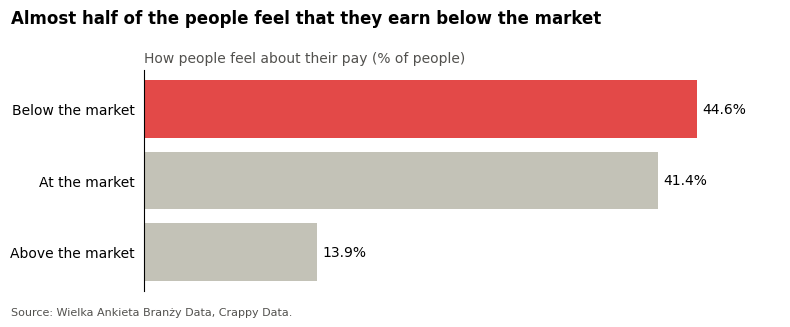

In [93]:
overall_feeling = known_feeling["feeling"].value_counts(normalize=True).loc[feeling_names] * 100

bar_chart(
    overall_feeling,
    "Almost half of the people feel that they earn below the market",
    "How people feel about their pay (% of people)",
    highlight=["Below the market"],
    number_format="{:.1f}%",
    color=RED,
)

In [94]:
above_estimate = (known_feeling["pay_gap_%"] > 0).mean() * 100

print("People above the estimate (%):", round(above_estimate, 1))

People above the estimate (%): 49.4


## 4.2 Compare reality and feeling

First, we count people in each combination.

In [95]:
feeling_counts = pd.crosstab(known_feeling["real_position"], known_feeling["feeling"])
feeling_counts = feeling_counts[feeling_names]
feeling_counts

feeling,Below the market,At the market,Above the market
real_position,,,
10%+ below similar people,61,21,6
Within 10%,29,34,9
10%+ above similar people,22,49,20


Now we change the counts to percentages in each row.

In [96]:
feeling_shares = pd.crosstab(known_feeling["real_position"], known_feeling["feeling"], normalize="index") * 100
feeling_shares = feeling_shares[feeling_names].round(1)

This chart shows the percentages.

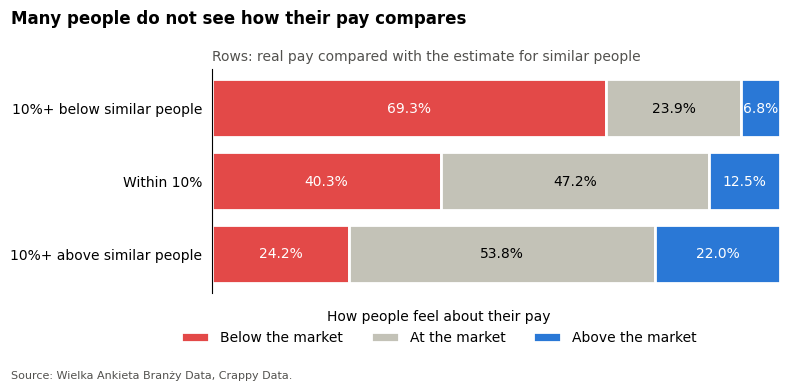

In [97]:
colors = {"Below the market": RED, "At the market": GRAY, "Above the market": BLUE}
text_colors = {"Below the market": "white", "At the market": "black", "Above the market": "white"}

fig, ax = plt.subplots(figsize=(8, 3.8))

# Draw one colored part at a time
left_edge = np.zeros(len(feeling_shares))
for feeling in feeling_names:
    values = feeling_shares[feeling].values
    bars = ax.barh(feeling_shares.index.astype(str), values, left=left_edge, color=colors[feeling], label=feeling, edgecolor="white", linewidth=2)
    ax.bar_label(bars, [f"{value:.1f}%" for value in values], label_type="center", color=text_colors[feeling])
    left_edge = left_edge + values

# Clean the chart and add the text
ax.invert_yaxis()
ax.set_xticks([])
ax.set_xlim(0, 100)
ax.legend(title="How people feel about their pay", ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.02), frameon=False)
fig.suptitle("Many people do not see how their pay compares", x=0.02, ha="left", fontweight="bold")
ax.set_title("Rows: real pay compared with the estimate for similar people", loc="left", fontsize=10, color=DARK_GRAY)
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

A **chi-square test** checks if feeling and real position are connected. Its assumption is that the expected count in each cell is at least 5, so we check this too.

In [98]:
chi_square = stats.chi2_contingency(feeling_counts)

print("p-value:", chi_square.pvalue)
print("Smallest expected count:", round(chi_square.expected_freq.min(), 1))

p-value: 7.28837151882259e-08
Smallest expected count: 10.0


**Cramér's V** shows the strength of the connection. It goes from 0 to 1. As a rough guide for this table, 0.07 is small, 0.21 is medium and 0.35 is large.

In [99]:
people = feeling_counts.values.sum()
cramers_v = np.sqrt(chi_square.statistic / (people * 2))

print("Cramér's V:", round(cramers_v, 2))

Cramér's V: 0.28


Finally, we count how many people have a feeling that matches their real position.

In [100]:
matches = {
    "10%+ below similar people": "Below the market",
    "Within 10%": "At the market",
    "10%+ above similar people": "Above the market",
}

expected_feeling = known_feeling["real_position"].astype(str).map(matches)
same_answer = known_feeling["feeling"] == expected_feeling

print("Feeling matches the estimate (%):", round(same_answer.mean() * 100, 1))

Feeling matches the estimate (%): 45.8


If there were no connection, this share would come only from how common each answer is. We calculate this share for comparison.

In [101]:
chance_share = 0
for real_position, feeling in matches.items():
    real_share = (known_feeling["real_position"] == real_position).mean()
    feeling_share = (known_feeling["feeling"] == feeling).mean()
    chance_share = chance_share + real_share * feeling_share

print("Match expected by chance (%):", round(chance_share * 100, 1))

Match expected by chance (%): 32.6


**What we see:**

- **People have some sense of their position.** Feeling and real position are clearly connected (p < 0.001), and the connection is medium to large (Cramér's V = 0.28). The test's assumption is met, because the smallest expected count is 10.0.
- **But the sense is not exact.** The feeling matches the estimate for 45.8% of people, compared with 32.6% expected by chance.
- **People who earn less usually know it.** Of people paid at least 10% below similar people, 69.3% feel that they earn below the market.
- **People who earn more often do not see it.** Of people paid at least 10% above similar people, only 22.0% feel that they earn above the market, and 24.2% still feel that they earn below it.

**This answers our first question.** Overall, 44.6% feel below the market and 13.9% feel above it. But about half of the people (49.4%) are above the estimate for similar people, so many people may be more pessimistic than the numbers suggest.

**Be careful:** the model is not the real job market. It does not see skills in detail, the exact city or results at work. So some people who feel underpaid may be right.

## 4.3 Do these results depend on our choices?

We made some important choices: the 10% limit, including all contract types and using Ridge. Now we change each choice and see if the main result stays.

This function calculates the main numbers for one check. It shows only the numbers that we need, so all groups stay large enough.

In [102]:
def check_result(data, groups, low_group, high_group):
    low_people = data[groups == low_group]
    high_people = data[groups == high_group]

    return {
        "people_in_low_group": len(low_people),
        "people_in_high_group": len(high_people),
        "low_group_feels_below_%": (low_people["feeling"] == "Below the market").mean() * 100,
        "high_group_feels_below_%": (high_people["feeling"] == "Below the market").mean() * 100,
        "high_group_feels_above_%": (high_people["feeling"] == "Above the market").mean() * 100,
    }

We start with the main result, so we can compare the checks with it.

In [103]:
checks = {}

low_name = "10%+ below similar people"
high_name = "10%+ above similar people"

checks["Main result (10% limit)"] = check_result(known_feeling, known_feeling["real_position"], low_name, high_name)

**Check 1:** a limit of 15%.

In [104]:
groups_15 = pd.cut(known_feeling["pay_gap_%"], bins=[-np.inf, -15, 15, np.inf], labels=["low", "middle", "high"])

checks["15% limit"] = check_result(known_feeling, groups_15, "low", "high")

**Check 2:** a limit of 30%. The model's errors are large, so people outside this limit are more clearly above or below similar people.

In [105]:
groups_30 = pd.cut(known_feeling["pay_gap_%"], bins=[-np.inf, -30, 30, np.inf], labels=["low", "middle", "high"])

checks["30% limit"] = check_result(known_feeling, groups_30, "low", "high")

**Check 3:** only full-time people with an employment contract.

In [106]:
is_employment = known_feeling["contract"] == "Employment contract"
is_full_time = known_feeling["work_time"] == "Full-time"
employment_feeling = known_feeling[is_employment & is_full_time]

checks["Employment contracts only"] = check_result(employment_feeling, employment_feeling["real_position"], low_name, high_name)

**Check 4:** we repeat the estimate with LightGBM and tools. This model also sees some of the person's skills.

In [107]:
lightgbm_estimate = cross_val_predict(
    make_model(tools_features, final_lightgbm),
    df[tools_features],
    df["log_pay"],
    cv=estimate_splits,
)

df["lightgbm_gap_%"] = (df["pay"] / np.exp(lightgbm_estimate) - 1) * 100
known_feeling["lightgbm_gap_%"] = df.loc[known_feeling.index, "lightgbm_gap_%"]

gap_correlation = df["pay_gap_%"].corr(df["lightgbm_gap_%"], method="spearman")
print("Spearman correlation between the two gaps:", round(gap_correlation, 2))

Spearman correlation between the two gaps: 0.91


In [108]:
lightgbm_groups = pd.cut(known_feeling["lightgbm_gap_%"], bins=gap_limits, labels=gap_names)

checks["LightGBM with tools"] = check_result(known_feeling, lightgbm_groups, low_name, high_name)

Now we put all results in one table.

In [109]:
checks_table = pd.DataFrame(checks).T
checks_table.round(1)

,people_in_low_group,people_in_high_group,low_group_feels_below_%,high_group_feels_below_%,high_group_feels_above_%
Main result (10% limit),88.0,91.0,69.3,24.2,22.0
15% limit,64.0,79.0,76.6,22.8,21.5
30% limit,23.0,43.0,91.3,23.3,27.9
Employment contracts only,68.0,72.0,70.6,27.8,15.3
LightGBM with tools,83.0,91.0,71.1,20.9,24.2


The chart shows the three shares for each check. If the points stay in similar places, the result does not depend on our choices.

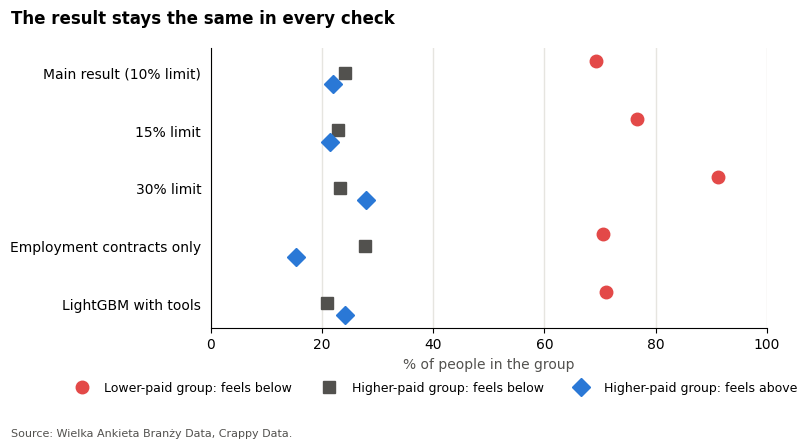

In [110]:
# Each series gets its own color, marker and small vertical shift, so the points do not cover each other
check_series = {
    "Lower-paid group: feels below": ("low_group_feels_below_%", RED, "o", -0.2),
    "Higher-paid group: feels below": ("high_group_feels_below_%", DARK_GRAY, "s", 0),
    "Higher-paid group: feels above": ("high_group_feels_above_%", BLUE, "D", 0.2),
}

fig, ax = plt.subplots(figsize=(8, 4.4))
rows = np.arange(len(checks_table))

for label, (column, color, marker, shift) in check_series.items():
    ax.plot(checks_table[column], rows + shift, marker, color=color, markersize=9, label=label)

ax.set_yticks(rows)
ax.set_yticklabels(checks_table.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of people in the group", color=DARK_GRAY)
ax.spines["bottom"].set_visible(True)
ax.grid(axis="x", color="#e6e5e0", linewidth=1)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.15), ncol=3, fontsize=9)

fig.suptitle("The result stays the same in every check", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**What we see:** the main pattern stays in all checks.

- **Most people in the lower-paid group feel below the market:** from 69.3% to 91.3%.
- **Only a small share of the higher-paid group feel above the market:** from 15.3% to 27.9%.
- **Some people in the higher-paid group still feel below the market:** from 20.9% to 27.8%.

The two models give very similar gaps (Spearman correlation = 0.91). With the 30% limit, the groups are smaller (23 and 43 people), so these numbers are less exact.

**Decision:** our conclusion does not depend on the limit, on B2B or on the model.

## 4.4 Which matters more for satisfaction: real position or feeling?

If people do not always know their real position, then which one goes together with job satisfaction? We compare both.

In [111]:
by_real_position = known_feeling.groupby("real_position", observed=True)["satisfaction"].mean()
by_feeling = known_feeling.groupby("feeling")["satisfaction"].mean().loc[feeling_names]

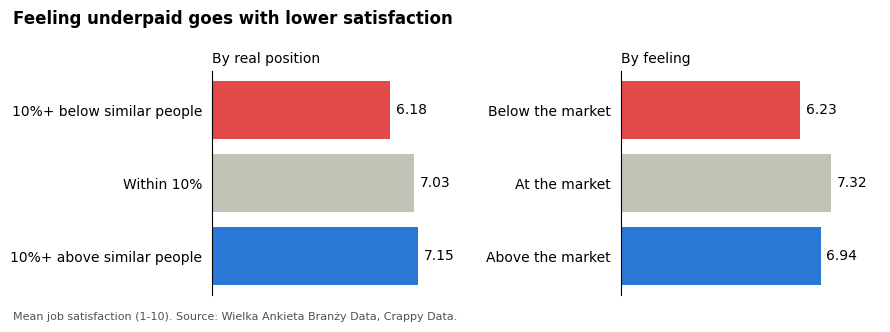

In [112]:
fig, (ax_real, ax_feeling) = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)

# Left: real position. Right: feeling.
real_bars = ax_real.barh(by_real_position.index.astype(str), by_real_position.values, color=[RED, GRAY, BLUE])
feeling_bars = ax_feeling.barh(by_feeling.index, by_feeling.values, color=[RED, GRAY, BLUE])
ax_real.bar_label(real_bars, [f"{value:.2f}" for value in by_real_position.values], padding=4)
ax_feeling.bar_label(feeling_bars, [f"{value:.2f}" for value in by_feeling.values], padding=4)

for ax in [ax_real, ax_feeling]:
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_xlim(0, 9)
ax_real.set_title("By real position", loc="left", fontsize=10)
ax_feeling.set_title("By feeling", loc="left", fontsize=10)

fig.suptitle("Feeling underpaid goes with lower satisfaction", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, "Mean job satisfaction (1-10). " + SOURCE, fontsize=8, color=DARK_GRAY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

We put both in one regression. `pay_gap_%` is the real position, and the yes/no columns are the feelings. People who feel "at the market" are the comparison group.

In [113]:
known_feeling["pay_gap_10"] = known_feeling["pay_gap_%"] / 10
known_feeling["feels_below"] = (known_feeling["feeling"] == "Below the market").astype(int)
known_feeling["feels_above"] = (known_feeling["feeling"] == "Above the market").astype(int)

satisfaction_model = smf.ols(
    "satisfaction ~ pay_gap_10 + feels_below + feels_above",
    data=known_feeling,
).fit(cov_type="HC3")

In [114]:
satisfaction_terms = ["pay_gap_10", "feels_below", "feels_above"]

pd.DataFrame({
    "points": satisfaction_model.params[satisfaction_terms],
    "ci_low": satisfaction_model.conf_int().loc[satisfaction_terms, 0],
    "ci_high": satisfaction_model.conf_int().loc[satisfaction_terms, 1],
    "p_value": satisfaction_model.pvalues[satisfaction_terms],
}).round(3)

,points,ci_low,ci_high,p_value
pay_gap_10,0.103,0.005,0.202,0.040
feels_below,-0.875,-1.441,-0.309,0.002
feels_above,-0.422,-1.227,0.384,0.305


**What we see:** both real position and feeling are connected with satisfaction when we look at them together.

- **Feeling below the market:** 0.88 points lower satisfaction (p = 0.002), compared with feeling at the market.
- **Real position:** when pay is 10 percentage points higher compared with similar people, satisfaction is only about 0.10 points higher (p = 0.040).
- **Feeling above the market:** no clear difference (p = 0.305).

**What it may mean:** a large real difference has a smaller connection with satisfaction than the feeling of being underpaid. For example, a gap of 20 percentage points goes with about 0.2 points.

**Be careful:** we cannot see which comes first. Unhappy people may also feel underpaid more easily.

## 4.5 What do people use to judge their pay?

Do people judge their pay by the amount itself, or by comparing it with similar people? We try to predict the feeling "below the market" with three different columns. **AUC** shows how well a model separates two groups: 0.5 is random, and 1.0 is perfect.

We use **logistic regression**, a simple model for yes/no questions.

In [115]:
feeling_target = known_feeling["feels_below"]
feeling_splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

feeling_inputs = {
    "Amount of pay": ["log_pay"],
    "Pay compared with similar people": ["pay_gap_%"],
    "Job, company and city": best_features,
}

In [116]:
feeling_scores = {}

for name, features in feeling_inputs.items():
    model = make_model(features, LogisticRegression(C=0.5, max_iter=3000))
    scores = cross_validate(model, known_feeling[features], feeling_target, cv=feeling_splits, scoring="roc_auc")
    feeling_scores[name] = scores["test_score"]

feeling_results = pd.DataFrame({
    "auc": [scores.mean() for scores in feeling_scores.values()],
    "auc_std": [scores.std() for scores in feeling_scores.values()],
}, index=feeling_scores.keys()).round(3)

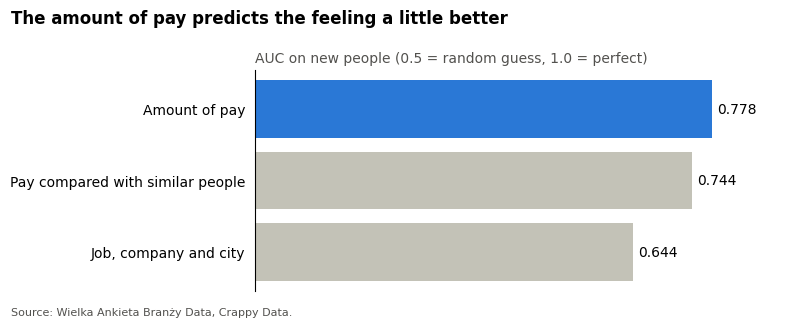

In [117]:
bar_chart(
    feeling_results["auc"],
    "The amount of pay predicts the feeling a little better",
    "AUC on new people (0.5 = random guess, 1.0 = perfect)",
    highlight=["Amount of pay"],
    number_format="{:.3f}",
)

The models use the same splits, so we can compare them split by split.

In [118]:
pay_auc = feeling_scores["Amount of pay"]
gap_auc = feeling_scores["Pay compared with similar people"]

print("Mean difference in AUC:", round((pay_auc - gap_auc).mean(), 3))
print("Splits where amount of pay is better (%):", round((pay_auc > gap_auc).mean() * 100))

Mean difference in AUC: 0.034
Splits where amount of pay is better (%): 64


**What we see:**

- **The amount of pay predicts the feeling best** (AUC = 0.778).
- **Pay compared with similar people is a little lower** (0.744).
- **Job, company and city are weaker** (0.644).

**What it may mean:** people may judge their pay more by the amount itself than by comparing it with similar people. But the difference is small (0.034), and amount of pay is better in only 64% of the splits. So this is only a weak hint and not strong evidence.

**What we learned in Part 4:** people have some sense of their market value, but it is not exact. Those who earn less usually know it. Those who earn more often do not see it.

---
# Conclusions

## What we found

| Question | Answer | How sure are we? |
|---|---|---|
| What matters most for pay? | Seniority and contract type | **High:** tests, regression and ML agree |
| Does the company matter? | International companies pay about 12-14% more than similar people get in Polish companies, and large companies about 10-12% more | **High** for capital, **medium** for size: both stay in the checks |
| Do skills matter? | Python users earn about 10-12% more than similar people | **Medium:** it stays in the checks, but not after the strictest skill correction |
| Do other tools matter? | Cloud data warehouses may matter (+9-12%) | **Low:** this result is not clear in the check |
| Does the place matter? | People in small towns have the lowest median pay | **Low to medium:** the effect is small and not clear after the correction |
| Does field of education matter? | We see no clear difference | **Medium:** the data keeps only one field |
| Is there a gender gap? | We see no clear gap | **Low to medium:** the interval is wide |
| Can we predict pay? | Partly: R² about 0.5 and a typical error of about 23% | **High:** tested on unseen people |
| Do people know their market value? | Partly: their feeling is connected with reality, but people who earn more often do not see it | **Medium:** the estimate is rough, so it works only for groups |

## Take-home messages

1. **Compare your pay with real data, not only with your feeling.** Many people who earn more than similar people do not feel it.
2. **Your employer may matter as much as your skills.** An international company and Python are connected with similar pay differences.
3. **If you work with data and do not use Python, it may be a good skill to learn next.** This is a connection and not a guarantee.
4. **Your field of study may not limit your pay in the long term.** Among similar people, we do not see a clear difference between fields.
5. **Compare B2B and employment offers carefully.** Take-home pay is much higher on B2B in this data (a median of 15,000 PLN compared with 8,200 PLN), but B2B usually has no paid holiday or sick leave.
6. **A complex model is not automatically better.** Default XGBoost was one of the weakest models. Tuned boosting was the most accurate, but simple linear models were close and are easier to explain.
7. **Better data may help more than a better algorithm.** The learning curves show that new information would probably help more than many more people.

## Limits of this project

- **No causes:** one survey shows connections and not causes.
- **Sample:** people chose to answer, so the results may not describe the whole industry.
- **Pay:** people were expected to give their average monthly pay after all taxes and ZUS, but we cannot be sure that everyone calculated it in this way, especially on B2B.
- **Skills:** we chose the skills after looking at the data, and no skill passed the strictest correction.
- **Results near p = 0.05:** some results change when we make a small change in the analysis. For example, when we added city size, large companies became clear and cloud data warehouses became unclear in the check for employment contracts. So we treat results near 0.05 as uncertain, and we trust more the results that stay the same in all checks.
- **The estimate:** the model does not see skills in detail, the exact city or results at work, so a person's "gap" is only a rough guide.

## What could come next

- Show a short example in the survey of how to calculate average monthly take-home pay, so that everyone uses the same method.
- Add the exact city or region and the exact skill level.
- Test the skill results on new survey data.

*Source: Wielka Ankieta Branży Data, Crappy Data.*